# Comparative Evaluation of Human-Centered vs. Baseline Navigation Agents

In [29]:
%matplotlib inline
import ipynbname
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
import seaborn as sns
import sys
from typing import Any, Dict

FILE_PATH = Path(ipynbname.path()).resolve()
PROJECT_ROOT = FILE_PATH.parents[1]
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

RAW_DATA_DIR = PROJECT_ROOT / "data" / "outputs" / "raw"
SAVE_DATA_DIR = PROJECT_ROOT / "data" / "outputs" / "processed"

sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["lines.linewidth"] = 2.0
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 12
%config InlineBackend.figure_format = "retina"

PID_COLOR = "#0d3b66"
FUZZY_COLOR = "#af1b3f"

print("Setup Complete.")

Setup Complete.


## Scenario 1: Longitudinal Path Tracking and Speed Control

In [30]:
SCENE_1_RAW_DIR = RAW_DATA_DIR / "scene_1_path_track"

path_baseline_ts = SCENE_1_RAW_DIR / "baseline_timeseries.csv"
path_baseline_col = SCENE_1_RAW_DIR / "baseline_collisions.csv"
path_baseline_inv = SCENE_1_RAW_DIR / "baseline_lane_invasions.csv"

path_fuzzy_ts = SCENE_1_RAW_DIR / "fuzzy_timeseries.csv"
path_fuzzy_col = SCENE_1_RAW_DIR / "fuzzy_collisions.csv"
path_fuzzy_inv = SCENE_1_RAW_DIR / "fuzzy_lane_invasions.csv"

In [31]:
SCENE_1_SAVE_DIR = SAVE_DATA_DIR / "scene_1_path_track"

path_velocity_comparison = SCENE_1_SAVE_DIR / "velocity_tracking_comparison.csv"
path_jerk_comparison = SCENE_1_SAVE_DIR / "longitudinal_jerk_comparison.csv"
path_actuator_comparison = SCENE_1_SAVE_DIR / "actuator_command_comparison.csv"

path_benchmarks_comparison = SCENE_1_SAVE_DIR / "benchmarks_comparison.csv"

In [32]:
def preprocess_timeseries_data(
    file_path: Path,
) -> pd.DataFrame:
    df = pd.read_csv(file_path)

    # Normalize Time
    df["relative_time"] = df["timestamp"] - df["timestamp"].iloc[0]

    # Calculate Current Speed
    df["current_speed_kmh"] = 3.6 * np.sqrt(
        df["velocity_x"] ** 2 + df["velocity_y"] ** 2 + df["velocity_z"] ** 2
    )

    # Calculate Signed Longitudinal Acceleration
    df["longitudinal_acceleration"] = (
        (df["acceleration_x"] * df["forward_x"])
        + (df["acceleration_y"] * df["forward_y"])
        + (df["acceleration_z"] * df["forward_z"])
    )

    # Calculate Longitudinal Jerk
    delta_accel = df["longitudinal_acceleration"].diff()
    delta_time = df["relative_time"].diff()
    df["longitudinal_jerk"] = delta_accel / delta_time
    df["longitudinal_jerk"] = df["longitudinal_jerk"].fillna(0.0)

    # Calculate Unified Control Intent
    df["control_intent"] = df["control_throttle"] - df["control_brake"]

    # Calculate Total Traversed Euclidean Distance
    dist_diff = np.sqrt(df["location_x"].diff() ** 2 + df["location_y"].diff() ** 2)
    df["distance_m"] = dist_diff.cumsum().fillna(0.0)

    return df

In [33]:
try:
    df_baseline_ts = preprocess_timeseries_data(path_baseline_ts)
    df_baseline_col = pd.read_csv(path_baseline_col)
    df_baseline_inv = pd.read_csv(path_baseline_inv)

    df_fuzzy_ts = preprocess_timeseries_data(path_fuzzy_ts)
    df_fuzzy_col = pd.read_csv(path_fuzzy_col)
    df_fuzzy_inv = pd.read_csv(path_fuzzy_inv)

except FileNotFoundError as e:
    print(f"CRITICAL ERROR: Could not find data file!\n{e}")

### Velocity Tracking Response

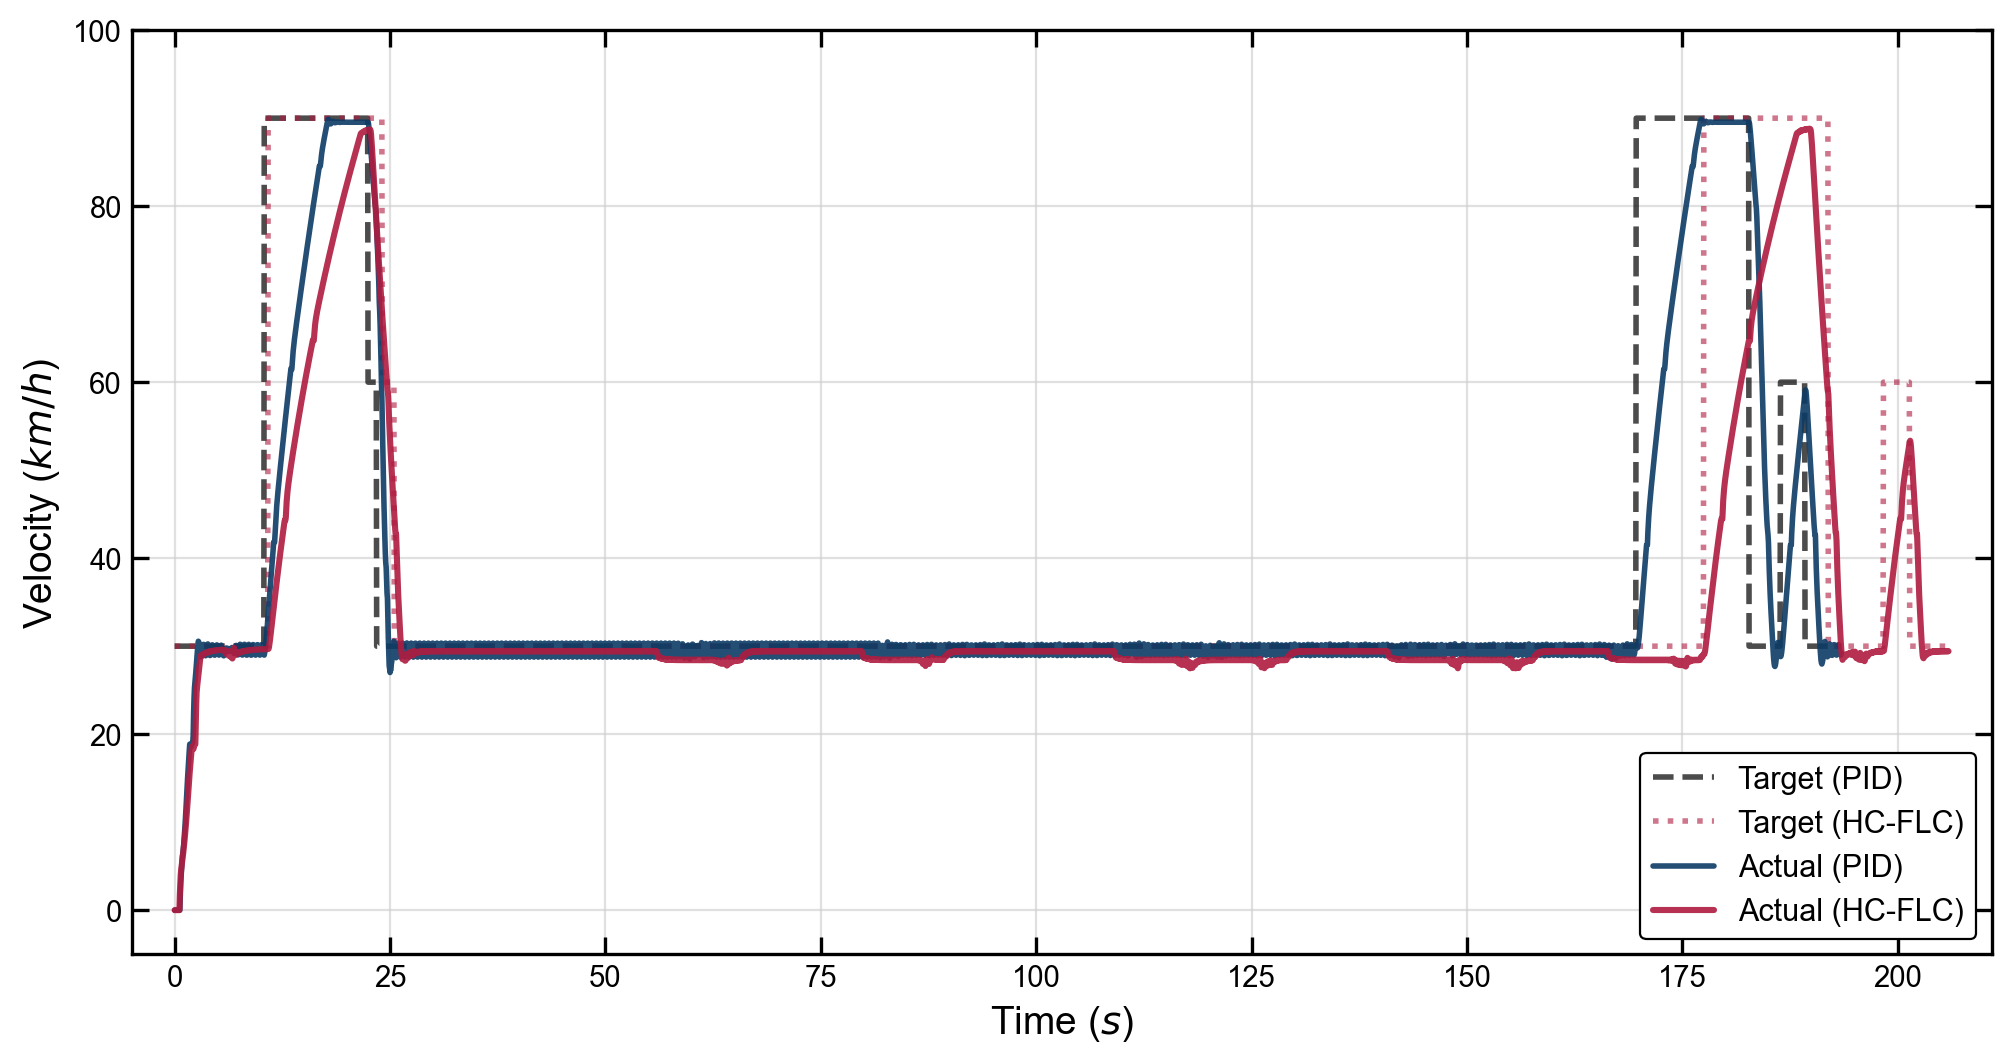

In [34]:
plt.figure(figsize=(12, 6))

# Plot Baseline Target Speed Reference
plt.plot(
    df_baseline_ts["relative_time"],
    df_baseline_ts["target_speed_kmh"],
    label="Target (PID)",
    color="#000000",
    linestyle="--",
    linewidth=2.0,
    alpha=0.7,
)

# Plot Fuzzy Target Speed Reference
plt.plot(
    df_fuzzy_ts["relative_time"],
    df_fuzzy_ts["target_speed_kmh"],
    label="Target (HC-FLC)",
    color=FUZZY_COLOR,
    linestyle=":",
    linewidth=2.0,
    alpha=0.6,
)

# Plot Baseline Current Speed
plt.plot(
    df_baseline_ts["relative_time"],
    df_baseline_ts["current_speed_kmh"],
    label="Actual (PID)",
    color=PID_COLOR,
    linewidth=2.0,
    alpha=0.9,
)

# Plot Fuzzy Current Speed
plt.plot(
    df_fuzzy_ts["relative_time"],
    df_fuzzy_ts["current_speed_kmh"],
    label="Actual (HC-FLC)",
    color=FUZZY_COLOR,
    linewidth=2.2,
    alpha=0.9,
)

# ----------- Plot Styling-----------
plt.xlabel("Time ($s$)", fontsize=14, color="black")
plt.ylabel("Velocity ($km/h$)", fontsize=14, color="black")

plt.legend(
    loc="best",
    frameon=True,
    fontsize=11,
    facecolor="white",
    framealpha=1.0,
    edgecolor="black",
    labelcolor="black",
)

plt.grid(True, which="major", linestyle="-", alpha=0.6)
plt.xlim(
    -5.0,
    max(df_baseline_ts["relative_time"].max(), df_fuzzy_ts["relative_time"].max())
    + 5.0,
)
plt.ylim(-5.0, 100)

ax = plt.gca()
ax.tick_params(
    axis="both",
    which="both",
    direction="in",
    color="black",
    labelcolor="black",
    length=6,
    width=1.2,
    bottom=True,
    top=True,
    left=True,
    right=True,
)
ax.xaxis.get_major_ticks()[0].label1.set_visible(False)
for spine in ax.spines.values():
    spine.set_edgecolor("black")
    spine.set_linewidth(1.2)

plt.show()

In [35]:
df_export_baseline = df_baseline_ts[
    ["relative_time", "target_speed_kmh", "current_speed_kmh"]
].rename(
    columns={
        "relative_time": "baseline_time_s",
        "target_speed_kmh": "baseline_target_kmh",
        "current_speed_kmh": "baseline_speed_kmh",
    }
)
df_export_fuzzy = df_fuzzy_ts[
    ["relative_time", "target_speed_kmh", "current_speed_kmh"]
].rename(
    columns={
        "relative_time": "fuzzy_time_s",
        "target_speed_kmh": "fuzzy_target_kmh",
        "current_speed_kmh": "fuzzy_speed_kmh",
    }
)

df_comparison = pd.concat([df_export_baseline, df_export_fuzzy], axis=1)
df_comparison.to_csv(path_velocity_comparison, index=False)

### Longitudinal Jerk Profile

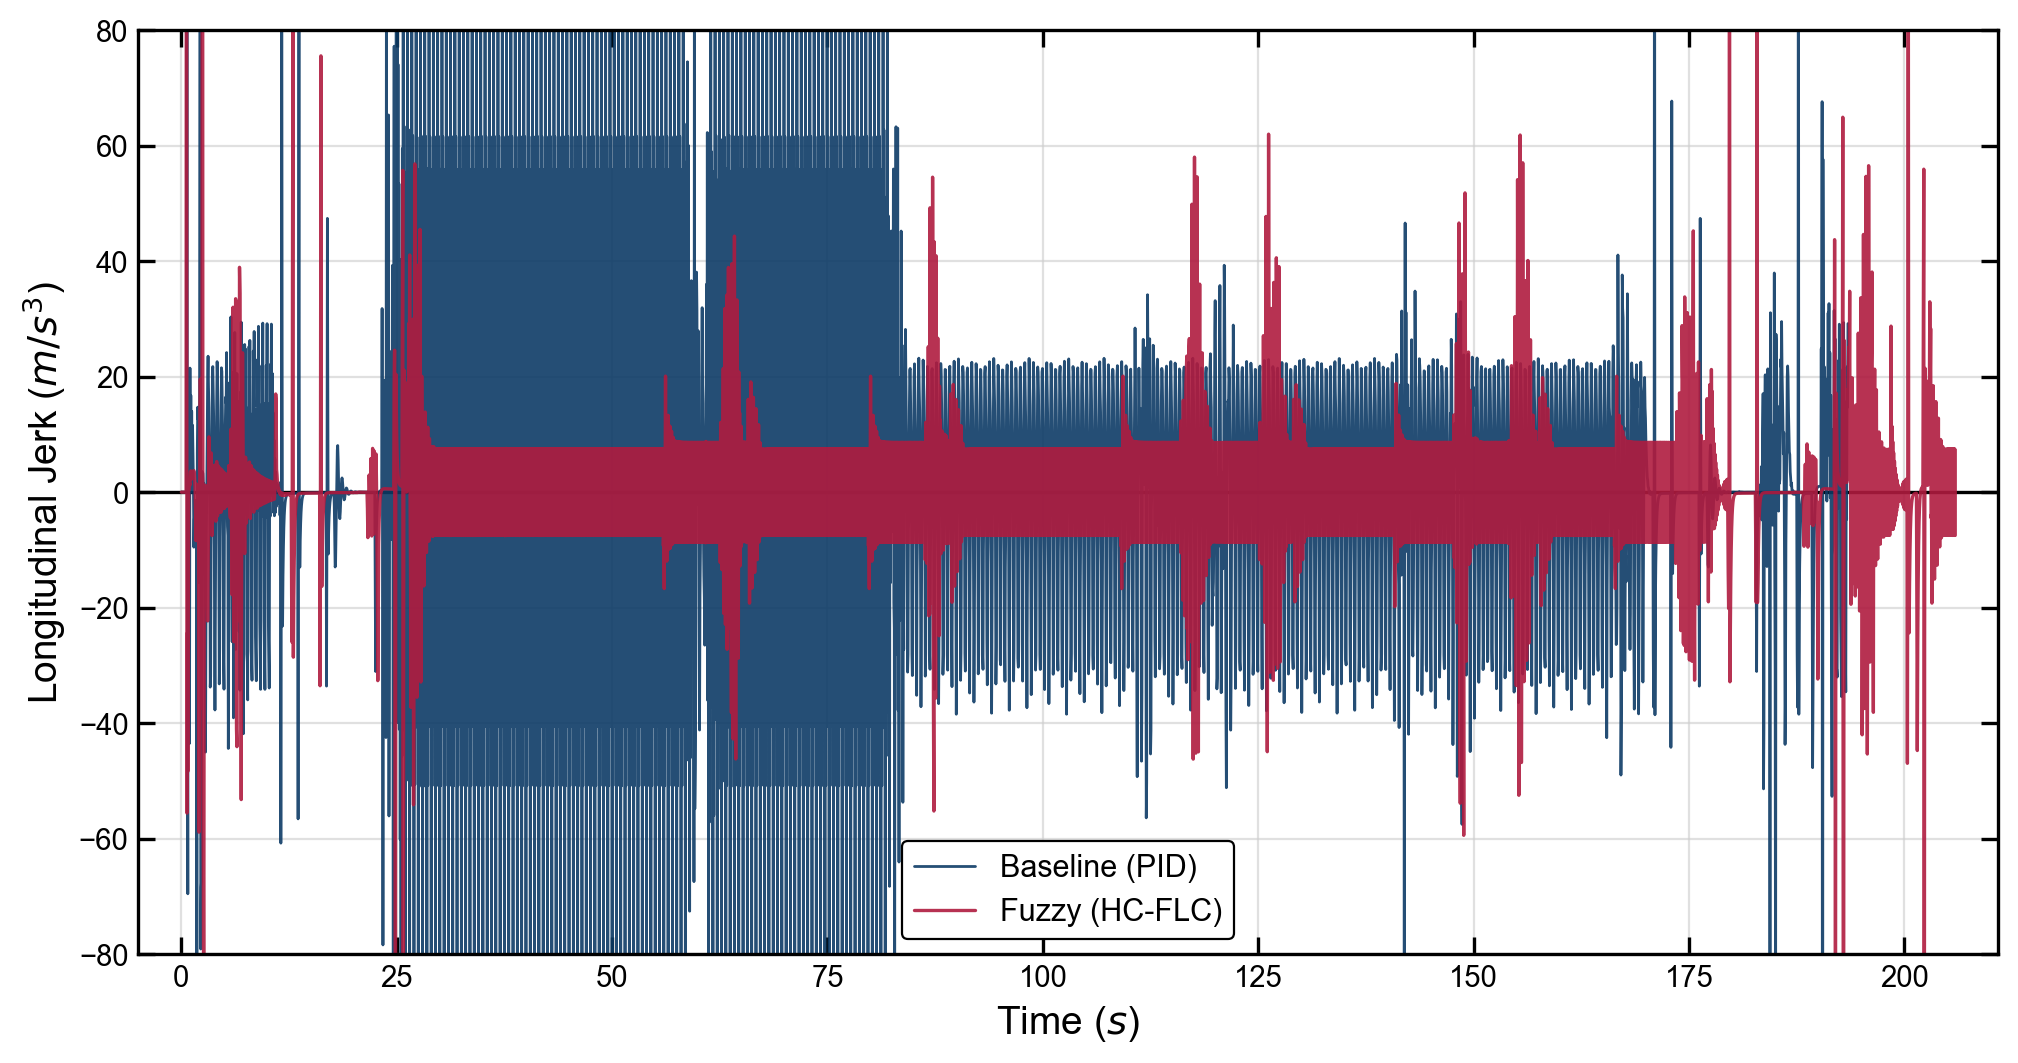

In [36]:
plt.figure(figsize=(12, 6))
plt.axhline(0, color="black", linestyle="-", linewidth=1.2, alpha=1.0)

# Plot Baseline Longitudinal Jerk
plt.plot(
    df_baseline_ts["relative_time"],
    df_baseline_ts["longitudinal_jerk"],
    label="Baseline (PID)",
    color=PID_COLOR,
    linewidth=1.0,
    alpha=0.9,
)

# Plot Fuzzy Longitudinal Jerk
plt.plot(
    df_fuzzy_ts["relative_time"],
    df_fuzzy_ts["longitudinal_jerk"],
    label="Fuzzy (HC-FLC)",
    color=FUZZY_COLOR,
    linewidth=1.2,
    alpha=0.9,
)

# ----------- Plot Styling -----------
plt.xlabel("Time ($s$)", fontsize=14, color="black")
plt.ylabel("Longitudinal Jerk ($m/s^3$)", fontsize=14, color="black")

plt.legend(
    loc="best",
    frameon=True,
    fontsize=11,
    facecolor="white",
    framealpha=1.0,
    edgecolor="black",
    labelcolor="black",
)

plt.grid(True, which="major", linestyle="-", alpha=0.6)
plt.xlim(
    -5.0,
    max(df_baseline_ts["relative_time"].max(), df_fuzzy_ts["relative_time"].max())
    + 5.0,
)
plt.ylim(-80, 80)

ax = plt.gca()
ax.tick_params(
    axis="both",
    which="both",
    direction="in",
    color="black",
    labelcolor="black",
    length=6,
    width=1.2,
    bottom=True,
    top=True,
    left=True,
    right=True,
)
# ax.xaxis.get_major_ticks()[0].label1.set_visible(False)
for spine in ax.spines.values():
    spine.set_edgecolor("black")
    spine.set_linewidth(1.2)

plt.show()

In [37]:
df_export_baseline = df_baseline_ts[["relative_time", "longitudinal_jerk"]].rename(
    columns={
        "relative_time": "baseline_time_s",
        "longitudinal_jerk": "baseline_jerk_m_s3",
    }
)
df_export_fuzzy = df_fuzzy_ts[["relative_time", "longitudinal_jerk"]].rename(
    columns={"relative_time": "fuzzy_time_s", "longitudinal_jerk": "fuzzy_jerk_m_s3"}
)

df_comparison = pd.concat([df_export_baseline, df_export_fuzzy], axis=1)
df_comparison.to_csv(path_jerk_comparison, index=False)

### Actuator Command Signal

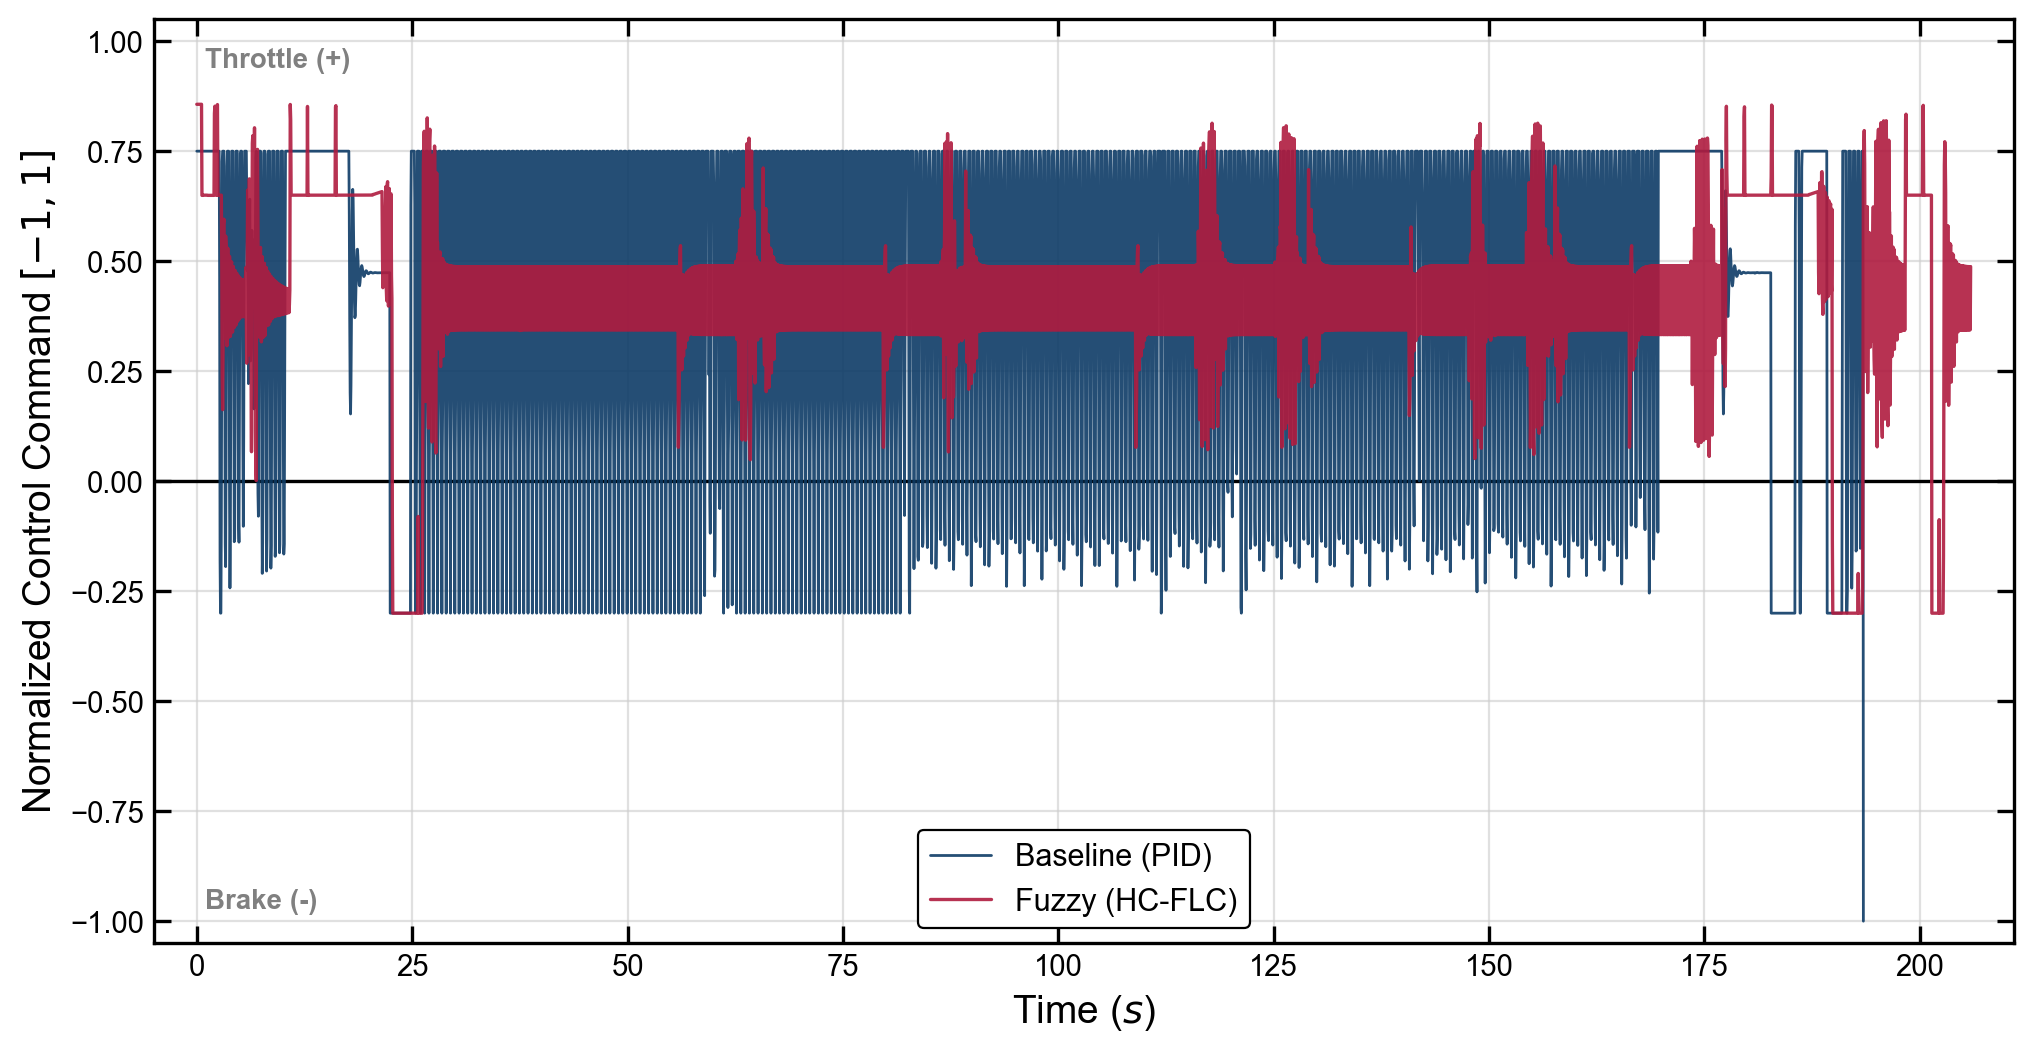

In [38]:
plt.figure(figsize=(12, 6))
plt.axhline(0, color="black", linestyle="-", linewidth=1.2, alpha=1.0)

# Plot Baseline Control Command
plt.plot(
    df_baseline_ts["relative_time"],
    df_baseline_ts["control_intent"],
    label="Baseline (PID)",
    color=PID_COLOR,
    linewidth=1.0,
    alpha=0.9,
)

# Plot Fuzzy Control Command
plt.plot(
    df_fuzzy_ts["relative_time"],
    df_fuzzy_ts["control_intent"],
    label="Fuzzy (HC-FLC)",
    color=FUZZY_COLOR,
    linewidth=1.2,
    alpha=0.9,
)

# ----------- Plot Styling -----------
plt.xlabel("Time ($s$)", fontsize=14, color="black")
plt.ylabel("Normalized Control Command $[-1, 1]$", fontsize=14, color="black")

plt.legend(
    loc="best",
    frameon=True,
    fontsize=11,
    facecolor="white",
    edgecolor="black",
    labelcolor="black",
    framealpha=1.0,
)

plt.grid(True, which="major", linestyle="-", alpha=0.6)

plt.xlim(
    -5.0,
    max(df_baseline_ts["relative_time"].max(), df_fuzzy_ts["relative_time"].max())
    + 5.0,
)
plt.ylim(-1.05, 1.05)

ax = plt.gca()
ax.tick_params(
    axis="both",
    which="both",
    direction="in",
    color="black",
    labelcolor="black",
    length=6,
    width=1.2,
    bottom=True,
    top=True,
    left=True,
    right=True,
)
ax.xaxis.get_major_ticks()[0].label1.set_visible(False)
for spine in ax.spines.values():
    spine.set_edgecolor("black")
    spine.set_linewidth(1.2)

plt.text(
    1.0,
    0.94,
    "Throttle (+)",
    fontsize=10,
    fontweight="bold",
    color="gray",
)
plt.text(
    1.0,
    -0.97,
    "Brake (-)",
    fontsize=10,
    fontweight="bold",
    color="gray",
)

plt.show()

In [39]:
df_export_baseline = df_baseline_ts[["relative_time", "control_intent"]].rename(
    columns={
        "relative_time": "baseline_time_s",
        "control_intent": "baseline_control_intent",
    }
)
df_export_fuzzy = df_fuzzy_ts[["relative_time", "control_intent"]].rename(
    columns={"relative_time": "fuzzy_time_s", "control_intent": "fuzzy_control_norm"}
)

df_comparison = pd.concat([df_export_baseline, df_export_fuzzy], axis=1)
df_comparison.to_csv(path_actuator_comparison, index=False)

### Performance Benchmarks

In [40]:
def compute_benchmarks(
    df_ts: pd.DataFrame,
    df_col: pd.DataFrame,
    df_inv: pd.DataFrame,
    agent_type: str,
) -> Dict[str, Any]:
    # Mission Efficiency
    total_duration = df_ts["relative_time"].iloc[-1]
    avg_speed = df_ts["current_speed_kmh"].mean()

    # Tracking Accuracy
    velocity_error = df_ts["target_speed_kmh"] - df_ts["current_speed_kmh"]
    velocity_rmse = np.sqrt((velocity_error**2).mean())

    # Ride Comfort
    avg_abs_jerk = df_ts["longitudinal_jerk"].abs().mean()
    peak_jerk = df_ts["longitudinal_jerk"].abs().max()

    # Vehicle Dynamics
    peak_speed = df_ts["current_speed_kmh"].max()
    peak_accel = df_ts["longitudinal_acceleration"].max()
    peak_decel = df_ts["longitudinal_acceleration"].min()

    # Control Stability
    control_std = df_ts["control_intent"].std()

    # Safety
    collision_count = len(df_col)
    invasion_count = len(df_inv)

    return {
        "Agent": agent_type,
        "Total Travel Time (s)": total_duration,
        "Average Velocity (km/h)": avg_speed,
        "Velocity RMSE (km/h)": velocity_rmse,
        "Average Absolute Jerk (m/s^3)": avg_abs_jerk,
        "Peak Jerk (m/s^3)": peak_jerk,
        "Peak Speed (km/h)": peak_speed,
        "Peak Acceleration (m/s^2)": peak_accel,
        "Peak Deceleration (m/s^2)": peak_decel,
        "Control Stability (std)": control_std,
        "Collision Count": collision_count,
        "Invasion Count": invasion_count,
    }

In [41]:
baseline_metrics = compute_benchmarks(
    df_baseline_ts, df_baseline_col, df_baseline_inv, "Baseline (PID)"
)
fuzzy_metrics = compute_benchmarks(
    df_fuzzy_ts, df_fuzzy_col, df_fuzzy_inv, "Fuzzy (HC-FLC)"
)

df_benchmark = pd.DataFrame([baseline_metrics, fuzzy_metrics])
df_benchmark = df_benchmark.set_index("Agent").T

df_benchmark.loc["Total Travel Time (s)"] = df_benchmark.loc[
    "Total Travel Time (s)"
].apply(lambda x: round(x, 2))
df_benchmark.loc["Average Velocity (km/h)"] = df_benchmark.loc[
    "Average Velocity (km/h)"
].apply(lambda x: round(x, 2))

df_benchmark.loc["Velocity RMSE (km/h)"] = df_benchmark.loc[
    "Velocity RMSE (km/h)"
].apply(lambda x: round(x, 2))

df_benchmark.loc["Average Absolute Jerk (m/s^3)"] = df_benchmark.loc[
    "Average Absolute Jerk (m/s^3)"
].apply(lambda x: round(x, 2))
df_benchmark.loc["Peak Jerk (m/s^3)"] = df_benchmark.loc["Peak Jerk (m/s^3)"].apply(
    lambda x: round(x, 2)
)

df_benchmark.loc["Peak Speed (km/h)"] = df_benchmark.loc["Peak Speed (km/h)"].apply(
    lambda x: round(x, 2)
)
df_benchmark.loc["Peak Acceleration (m/s^2)"] = df_benchmark.loc[
    "Peak Acceleration (m/s^2)"
].apply(lambda x: round(x, 2))
df_benchmark.loc["Peak Deceleration (m/s^2)"] = df_benchmark.loc[
    "Peak Deceleration (m/s^2)"
].apply(lambda x: round(x, 2))

df_benchmark.loc["Control Stability (std)"] = df_benchmark.loc[
    "Control Stability (std)"
].apply(lambda x: round(x, 2))

df_benchmark.loc["Collision Count"] = df_benchmark.loc["Collision Count"].astype(int)
df_benchmark.loc["Invasion Count"] = df_benchmark.loc["Invasion Count"].astype(int)

df_benchmark.to_csv(path_benchmarks_comparison, index=True)

In [42]:
display(df_benchmark)

Agent,Baseline (PID),Fuzzy (HC-FLC)
Total Travel Time (s),193.45,205.90
Average Velocity (km/h),36.37,34.53
Velocity RMSE (km/h),11.10,11.23
Average Absolute Jerk (m/s^3),23.97,8.70
Peak Jerk (m/s^3),241.48,275.42
Peak Speed (km/h),89.87,88.80
Peak Acceleration (m/s^2),13.76,13.74
Peak Deceleration (m/s^2),-12.97,-9.97
Control Stability (std),0.37,0.20
Collision Count,0.00,0.00
